In [47]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
import warnings
from pathlib import Path
from scripts.data_loading import read_all
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.metrics import r2_score

In [17]:
REPO_ROOT = Path.cwd().parent
TRAIN = REPO_ROOT / "data" / "train"

train_input = read_all(TRAIN, "input_*.csv")
train_output = read_all(TRAIN, "output_*.csv")

KEYS = ["game_id", "play_id", "nfl_id"]

train/input_*.csv: found 18 files
train/output_*.csv: found 18 files


In [18]:
warnings.filterwarnings("ignore")

def split_by_game(inp, out, test_frac=0.2, seed=42):
    games = inp["game_id"].unique().copy()
    np.random.default_rng(seed).shuffle(games)
    test_games = set(games[:int(len(games) * test_frac)])

    in_test = inp["game_id"].isin(test_games)
    out_test = out["game_id"].isin(test_games)

    return (
        inp[~in_test].reset_index(drop=True),
        inp[in_test].reset_index(drop=True),
        out[~out_test].reset_index(drop=True),
        out[out_test].reset_index(drop=True),
    )


train_in, test_in, train_out, test_out = split_by_game(
    train_input, train_output
)

print(
    "Test games:", test_in["game_id"].nunique(),
    "| Test plays:", test_in[["game_id", "play_id"]].drop_duplicates().shape[0]
)

Test games: 54 | Test plays: 2765


In [19]:
warnings.filterwarnings("ignore")

def forecast_series(values, n_future_frames, order=(1, 1, 0)):
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return np.full(n_future_frames, values[-1])

    try:
        return np.asarray(ARIMA(values, order=order).fit().forecast(n_future_frames))
    except Exception:
        return np.full(n_future_frames, values[-1])

In [20]:
warnings.filterwarnings("ignore")

def forecast_players(inp, horizons, order=(1, 1, 0)):
    rows = []

    for key, g in inp.sort_values("frame_id").groupby(KEYS):
        if key not in horizons.index:
            continue

        n = int(horizons.loc[key])
        rows.append(pd.DataFrame({
            **dict(zip(KEYS, key)),
            "frame_id": np.arange(1, n + 1),
            "x_pred": forecast_series(g["x"], n, order),
            "y_pred": forecast_series(g["y"], n, order),
        }))

    return pd.concat(rows, ignore_index=True)


horizons = test_out.groupby(KEYS).size()
preds = forecast_players(test_in, horizons)

In [21]:
test_out = test_out.merge(
    preds, on=KEYS + ["frame_id"], how="left"
)

print("Rows without prediction:", test_out["x_pred"].isna().sum())
display(test_out.head())

Rows without prediction: 0


,game_id,play_id,nfl_id,frame_id,x,y,source_file,x_pred,y_pred
0,2023091002,110,53455,1,54.47,38.42,output_2023_w01,54.478392,38.417833
1,2023091002,110,53455,2,54.57,38.58,output_2023_w01,54.595197,38.563530
2,2023091002,110,53455,3,54.67,38.75,output_2023_w01,54.710437,38.707121
3,2023091002,110,53455,4,54.75,38.95,output_2023_w01,54.824132,38.848639
4,2023091002,110,53455,5,54.82,39.19,output_2023_w01,54.936304,38.988111


In [26]:
err = np.sqrt(((test_out["x"] - test_out["x_pred"]) ** 2 + (test_out["y"] - test_out["y_pred"]) ** 2).mean() / 2)
print("RMSE:", err)

RMSE: 1.8107152731829819


In [48]:
r2_score(test_out["x"], test_out["x_pred"])

0.9948122695558356

In [52]:
last = (test_in.sort_values("frame_id").groupby(KEYS)[["x", "y"]].last()
        .rename(columns={"x": "x0", "y": "y0"}).reset_index())
test_out = test_out.merge(last, on=KEYS, how="left")

for c in ["x", "y"]:
    print(f"R² deslocamento {c}:",
          r2_score(test_out[c] - test_out[c + "0"], test_out[c + "_pred"] - test_out[c + "0"]))

R² deslocamento x: 0.8735849270399374
R² deslocamento y: 0.7504518523819126


In [27]:
def draw_field(ax):
    ax.set(xlim=(0, 120), ylim=(0, 53.3), xlabel="x (yards)", ylabel="y (yards)")
    ax.set_aspect("equal")
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color="#3a7d44", zorder=0))
    ax.add_patch(Rectangle((0, 0), 10, 53.3, color="#2c5f34", zorder=0))
    ax.add_patch(Rectangle((110, 0), 10, 53.3, color="#2c5f34", zorder=0))

    for x in range(10, 111, 5):
        ax.axvline(x, color="white", lw=0.8 if x % 10 == 0 else 0.4,
                   alpha=0.7, zorder=1)


def plot_play(game_id, play_id, test_in, test_out):
    inp = test_in.query("game_id == @game_id and play_id == @play_id")
    out = test_out.query("game_id == @game_id and play_id == @play_id")

    if inp.empty:
        print("Play not found.")
        return

    fig, ax = plt.subplots(figsize=(14, 6.5))
    draw_field(ax)

    for nfl_id, g in inp.sort_values("frame_id").groupby("nfl_id"):
        o = out[out["nfl_id"] == nfl_id].sort_values("frame_id")
        name = g["player_name"].iloc[0]
        lx, ly = g["x"].iloc[-1], g["y"].iloc[-1]

        ax.plot(g["x"], g["y"], color="tab:blue", lw=1.8, zorder=3)

        if not o.empty:
            ax.plot([lx, *o["x"]], [ly, *o["y"]],
                    color="lime", lw=1.8, zorder=3)

            if o["x_pred"].notna().any():
                ax.plot([lx, *o["x_pred"]], [ly, *o["y_pred"]],
                        color="red", lw=1.8, ls="--", zorder=3)

        ax.scatter(lx, ly, s=25, color="white",
                   edgecolor="black", zorder=4)
        ax.annotate(name.split()[-1], (lx, ly), fontsize=7,
                    color="white", xytext=(3, 3),
                    textcoords="offset points")

    bx = inp["ball_land_x"].iloc[0]
    by = inp["ball_land_y"].iloc[0]
    ax.scatter(bx, by, marker="*", s=200, color="gold",
               edgecolor="black", zorder=5)

    ax.plot([], [], color="tab:blue", label="Input")
    ax.plot([], [], color="lime", label="True output")
    ax.plot([], [], color="red", ls="--", label="Predicted output")
    ax.scatter([], [], marker="*", s=120, color="gold",
               edgecolor="black", label="Ball landing")

    ax.legend(loc="upper right", fontsize=8)
    ax.set_title(f"Game {game_id}, Play {play_id}")
    plt.tight_layout()
    plt.show()

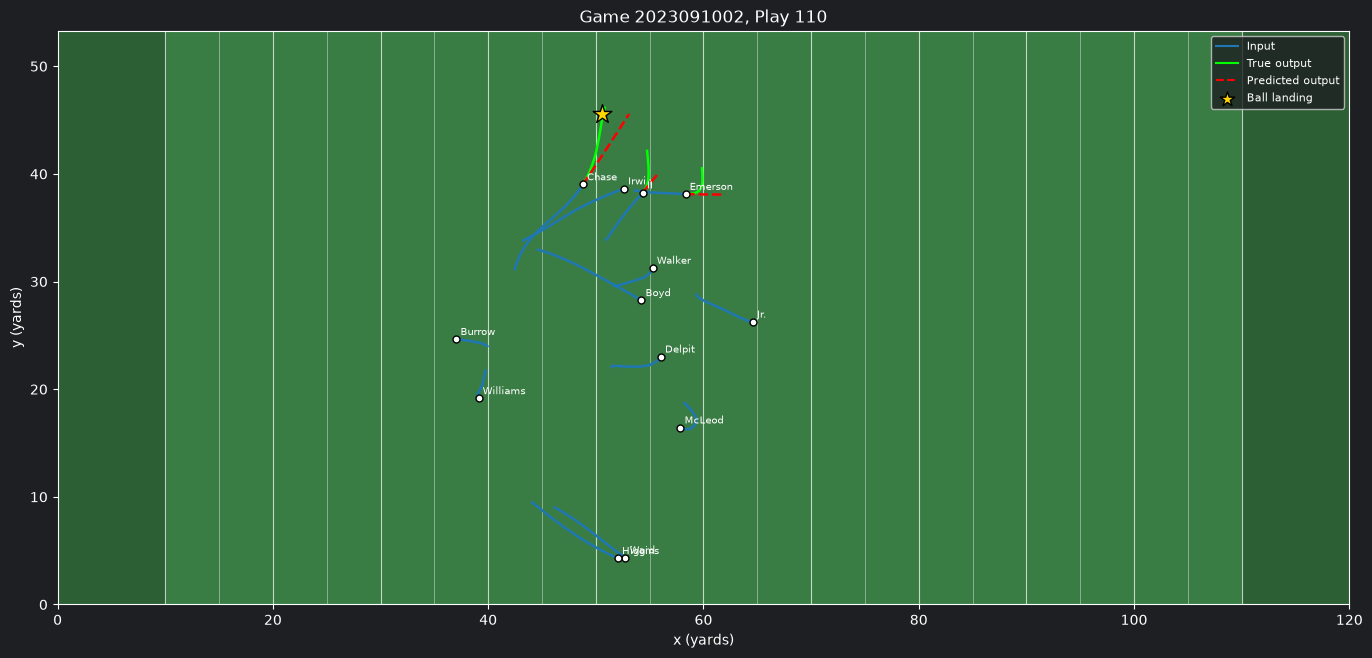

In [28]:
# first play in the test set
g0, p0 = test_in[["game_id", "play_id"]].iloc[0]
plot_play(g0, p0, test_in, test_out)

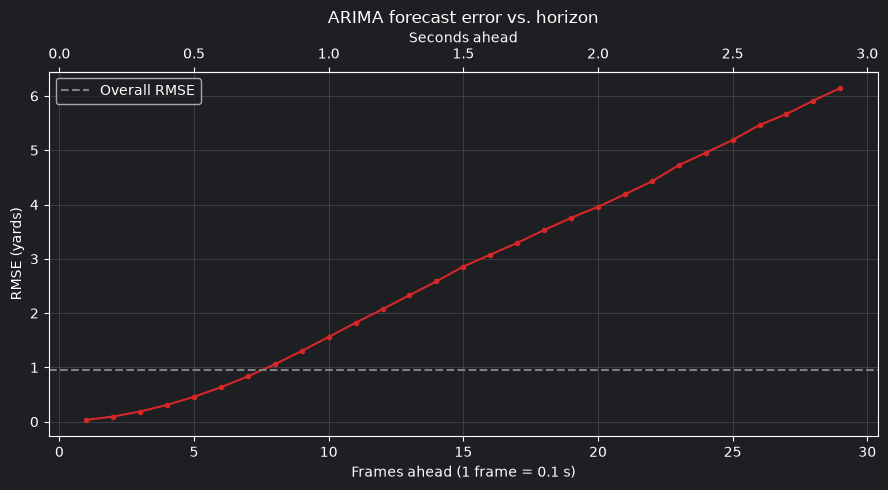

              rmse  count
frame_id                 
1         0.032849   8986
5         0.458775   8986
10        1.561063   5532
20        3.958067   1044
30        6.427121     89


In [30]:
test_out["se"] = ((test_out["x"] - test_out["x_pred"]) ** 2 +
                  (test_out["y"] - test_out["y_pred"]) ** 2)

by_h = test_out.groupby("frame_id")["se"].agg(["mean", "count"])
by_h["rmse"] = np.sqrt(by_h["mean"] / 2)

MIN_ROWS = 100
plot_df = by_h[by_h["count"] >= MIN_ROWS]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(plot_df.index, plot_df["rmse"], marker="o", ms=3, color="tab:red")
ax.axhline(np.sqrt(err.mean() / 2), color="gray", ls="--", label="Overall RMSE")
ax.set_xlabel("Frames ahead (1 frame = 0.1 s)")
ax.set_ylabel("RMSE (yards)")
ax.set_title("ARIMA forecast error vs. horizon")
ax.grid(alpha=0.3)
ax.legend()

secax = ax.secondary_xaxis("top", functions=(lambda f: f / 10, lambda s: s * 10))
secax.set_xlabel("Seconds ahead")

plt.tight_layout()
plt.show()

print(by_h.loc[[1, 5, 10, 20, 30], ["rmse", "count"]] if 30 in by_h.index else by_h.head())

In [36]:
print(test_in.drop_duplicates(KEYS).groupby("player_role")["player_to_predict"].mean())

player_role
Defensive Coverage    0.337566
Other Route Runner    0.000000
Passer                0.000000
Targeted Receiver     1.000000
Name: player_to_predict, dtype: float64


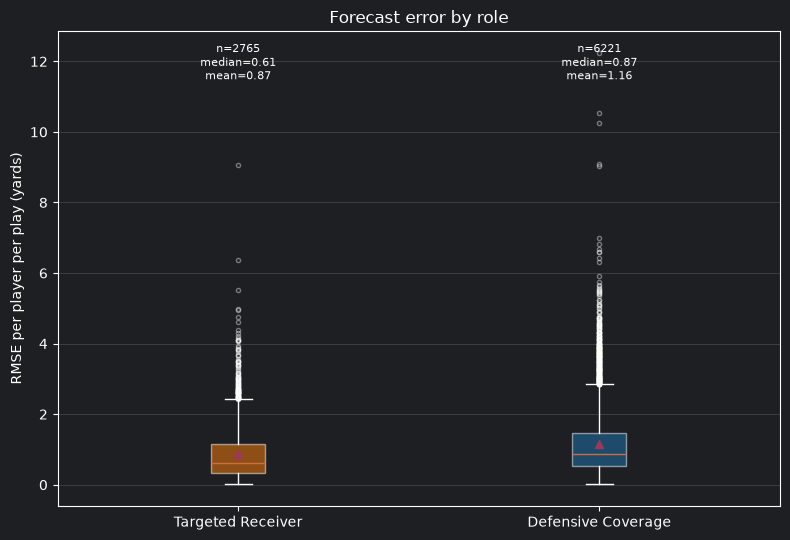

                     count   mean    std    min    25%    50%    75%     max
player_role                                                                 
Defensive Coverage  6221.0  1.160  0.955  0.011  0.534  0.874  1.461  12.240
Targeted Receiver   2765.0  0.866  0.775  0.013  0.325  0.612  1.168   9.076


In [41]:
ROLES = ["Targeted Receiver", "Defensive Coverage"]

per_player = (test_out[test_out["player_role"].isin(ROLES)]
              .groupby(KEYS + ["player_role"])["se"]
              .mean()
              .pipe(lambda s: np.sqrt(s / 2))
              .rename("rmse")
              .reset_index())

data = [per_player.loc[per_player["player_role"] == r, "rmse"] for r in ROLES]

fig, ax = plt.subplots(figsize=(8, 5.5))
bp = ax.boxplot(data, tick_labels=ROLES, showmeans=True, patch_artist=True,
                flierprops=dict(marker="o", markersize=3, alpha=0.4))
for patch, color in zip(bp["boxes"], ["tab:orange", "tab:blue"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax.set_ylabel("RMSE per player per play (yards)")
ax.set_title("Forecast error by role")
ax.grid(axis="y", alpha=0.3)

for i, d in enumerate(data, start=1):
    ax.annotate(f"n={len(d)}\nmedian={d.median():.2f}\nmean={d.mean():.2f}",
                (i, ax.get_ylim()[1]), xytext=(0, -8), textcoords="offset points",
                ha="center", va="top", fontsize=8)

plt.tight_layout()
plt.show()

print(per_player.groupby("player_role")["rmse"].describe().round(3))

In [42]:
names = test_in[KEYS + ["player_name"]].drop_duplicates(KEYS)
ranked = per_player.merge(names, on=KEYS, how="left")
cols = ["game_id", "play_id", "nfl_id", "player_name", "player_role", "rmse"]

top5 = ranked.sort_values("rmse", ascending=False).head(5)[cols]
print(top5.round(2).to_string(index=False))

per_player_cap = (test_out[test_out["player_role"].isin(ROLES) & (test_out["frame_id"] <= 30)]
                  .groupby(KEYS + ["player_role"])["se"]
                  .mean()
                  .pipe(lambda s: np.sqrt(s / 2))
                  .rename("rmse")
                  .reset_index())

ranked_cap = per_player_cap.merge(names, on=KEYS, how="left")
cols = ["game_id", "play_id", "nfl_id", "player_name", "player_role", "rmse"]

top5_cap = ranked_cap.sort_values("rmse", ascending=False).head(5)[cols]
print(top5_cap.round(2).to_string(index=False))

   game_id  play_id  nfl_id       player_name        player_role  rmse
2023122100     1450   53505     Paulson Adebo Defensive Coverage 12.24
2023122100     1450   54514    Alontae Taylor Defensive Coverage 10.53
2023122100     1450   55132      Nephi Sewell Defensive Coverage 10.25
2023091002     1260   54525  Cam Taylor-Britt Defensive Coverage  9.08
2023122100     1450   43415 Demarcus Robinson  Targeted Receiver  9.08
   game_id  play_id  nfl_id      player_name        player_role  rmse
2023091002     1260   54525 Cam Taylor-Britt Defensive Coverage  7.77
2023122100     1450   53505    Paulson Adebo Defensive Coverage  7.58
2023122408     3377   46269     Foye Oluokun Defensive Coverage  6.68
2023091702     2515   54496      Daxton Hill Defensive Coverage  6.60
2023102908     3160   55931     Sydney Brown Defensive Coverage  6.59


5 plays
      player_name        player_role  rmse
    Paulson Adebo Defensive Coverage 12.24
   Alontae Taylor Defensive Coverage 10.53
     Nephi Sewell Defensive Coverage 10.25
Demarcus Robinson  Targeted Receiver  9.08


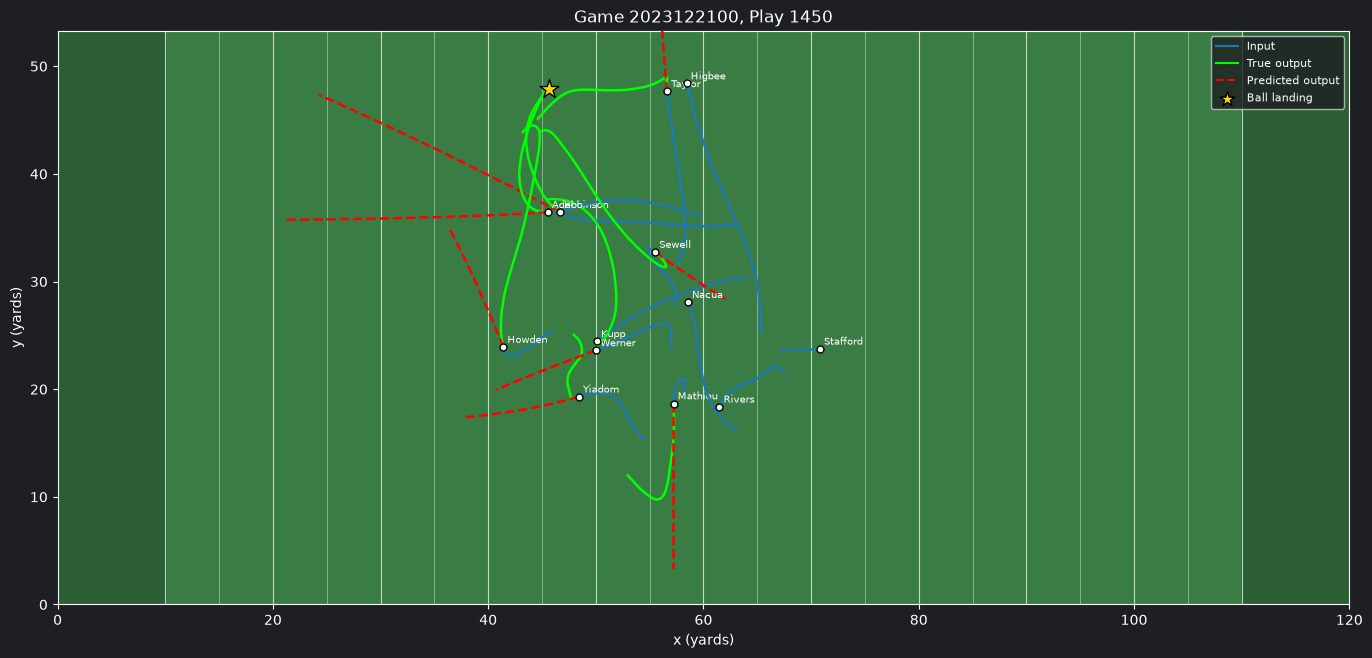

     player_name        player_role  rmse
Cam Taylor-Britt Defensive Coverage  9.08


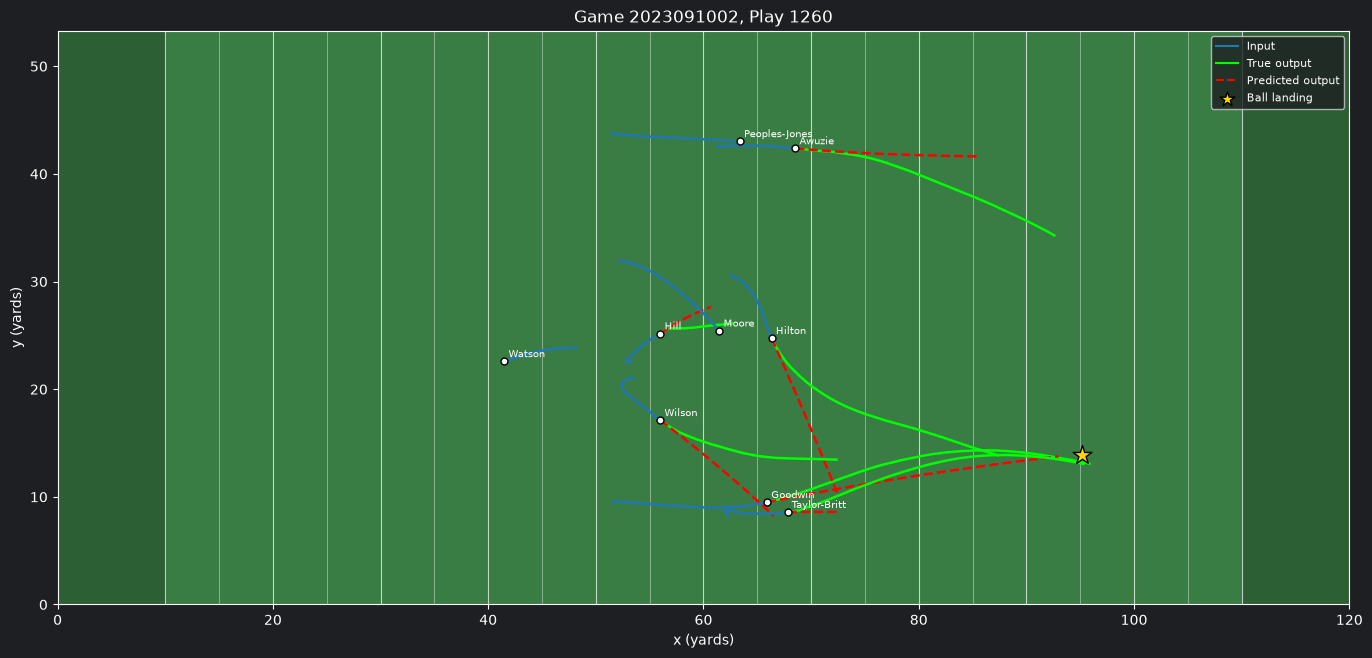

 player_name        player_role  rmse
Foye Oluokun Defensive Coverage  6.68


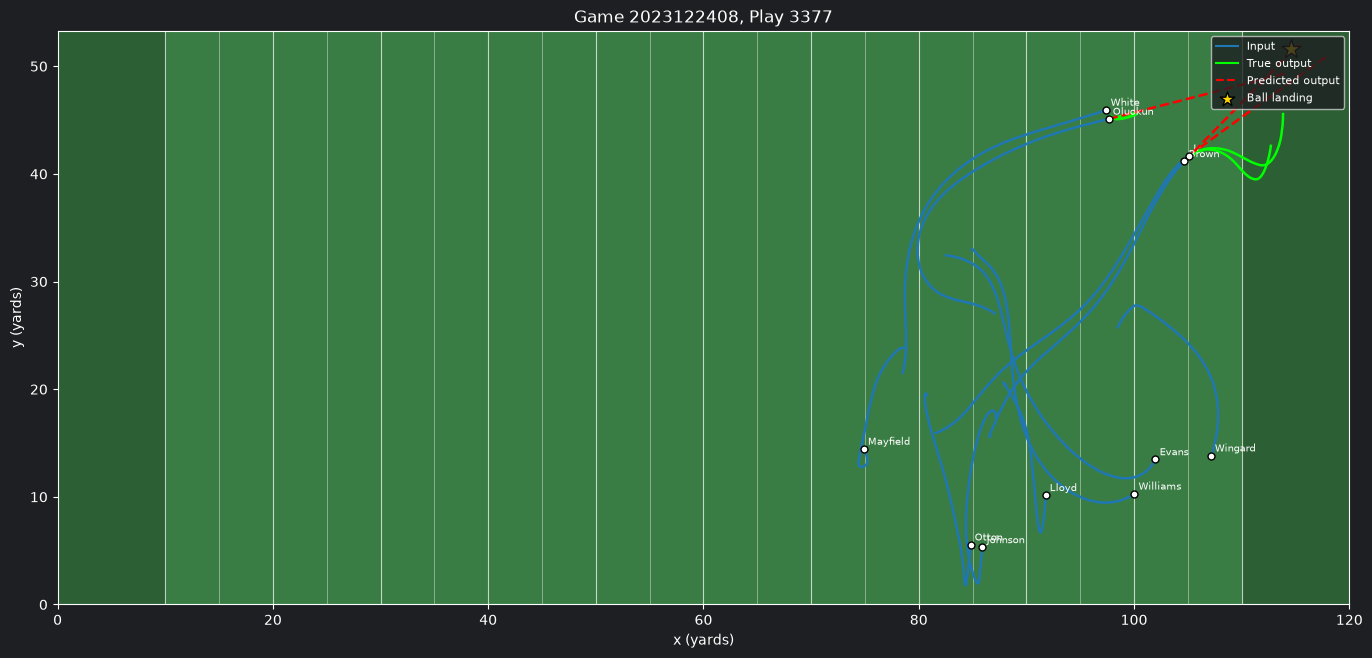

player_name        player_role  rmse
Daxton Hill Defensive Coverage   6.6


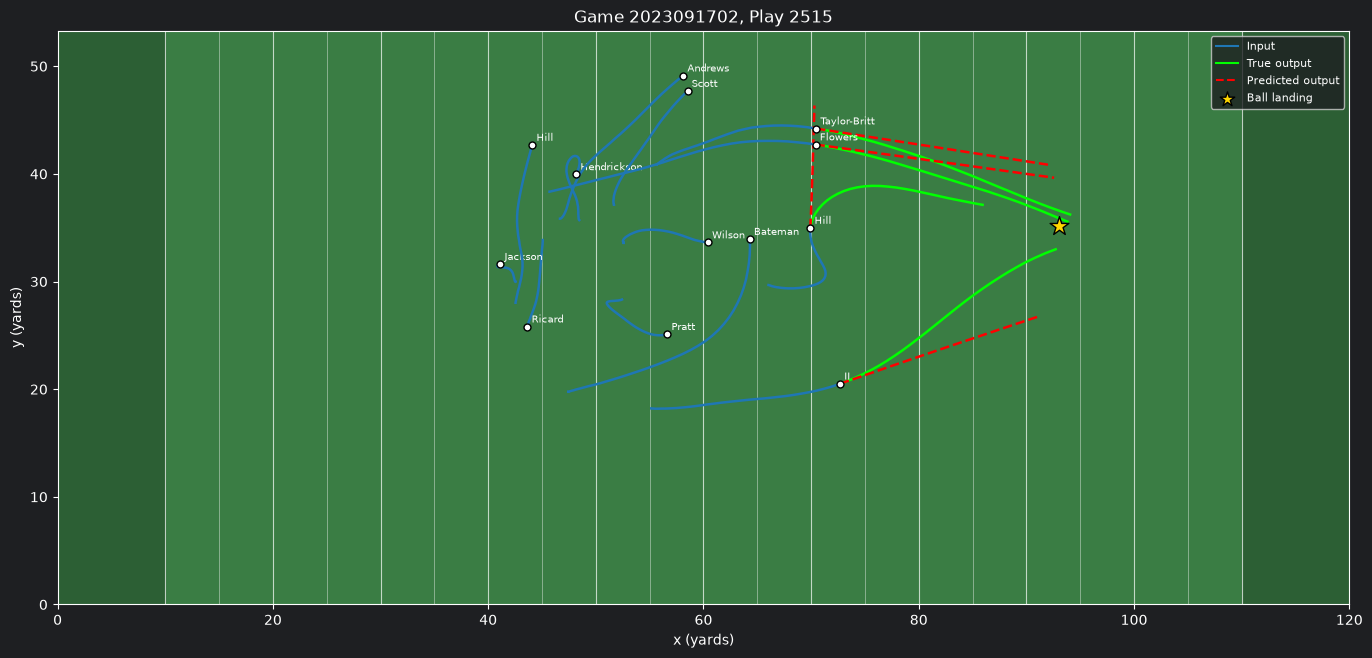

 player_name        player_role  rmse
Sydney Brown Defensive Coverage  6.59


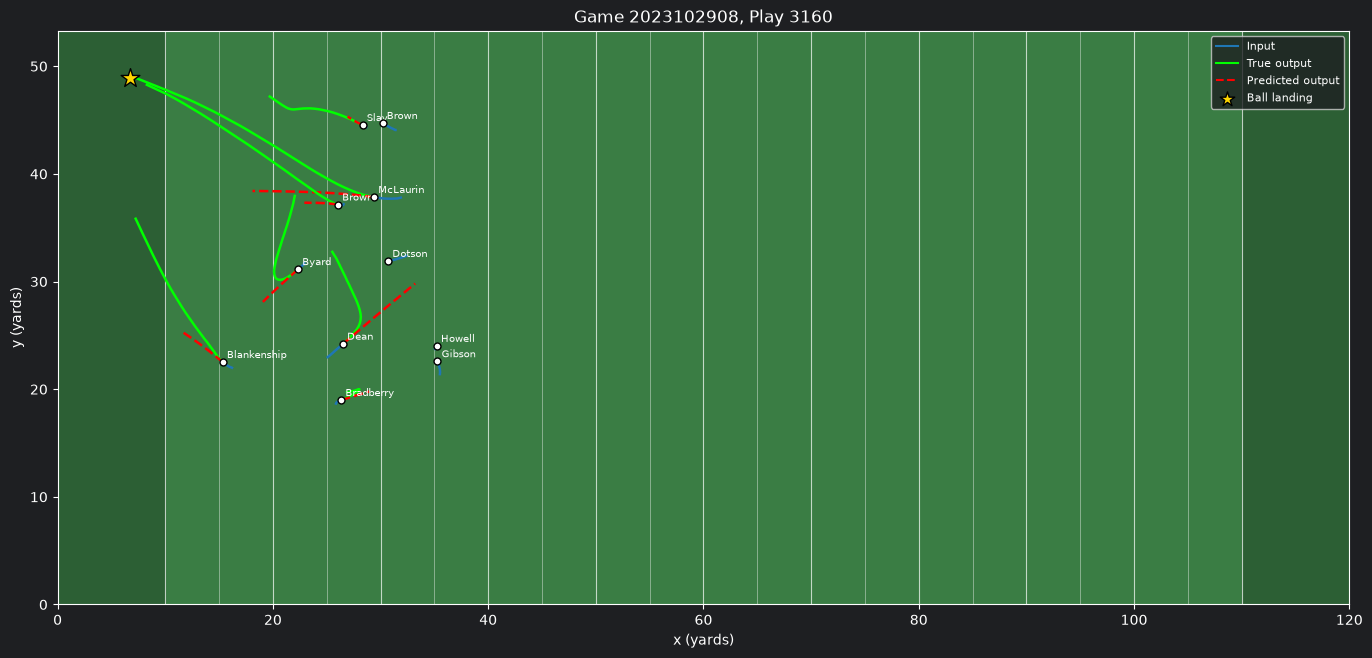

In [43]:
worst = pd.concat([top5, top5_cap]).drop_duplicates(KEYS)
plays = worst[["game_id", "play_id"]].drop_duplicates()

for gid, pid in plays.itertuples(index=False):
    print(worst[(worst["game_id"] == gid) & (worst["play_id"] == pid)]
          [["player_name", "player_role", "rmse"]].round(2).to_string(index=False))
    plot_play(gid, pid, test_in, test_out)

player_role
Defensive Coverage    0.049
Targeted Receiver     0.165
dtype: float64


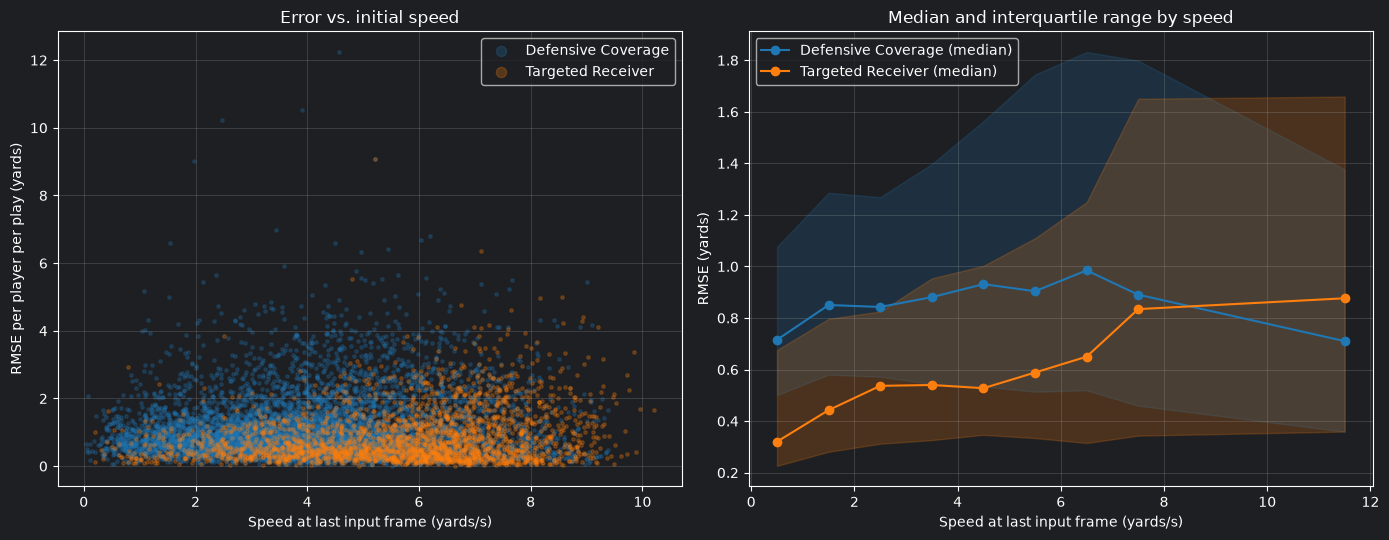

In [44]:
COLORS = {"Targeted Receiver": "tab:orange", "Defensive Coverage": "tab:blue"}

s_last = (test_in.sort_values("frame_id")
          .groupby(KEYS)["s"].last()
          .rename("s_last").reset_index())
sp = per_player.merge(s_last, on=KEYS, how="left")

print(sp.groupby("player_role").apply(
    lambda d: d["s_last"].corr(d["rmse"], method="spearman")).round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for role, g in sp.groupby("player_role"):
    ax1.scatter(g["s_last"], g["rmse"], s=6, alpha=0.25,
                color=COLORS.get(role), label=role)
ax1.set_xlabel("Speed at last input frame (yards/s)")
ax1.set_ylabel("RMSE per player per play (yards)")
ax1.set_title("Error vs. initial speed")
ax1.grid(alpha=0.3)
ax1.legend(markerscale=3)

bins = [0, 1, 2, 3, 4, 5, 6, 7, 8, 15]
sp["s_bin"] = pd.cut(sp["s_last"], bins=bins)
for role, g in sp.groupby("player_role"):
    stats = g.groupby("s_bin", observed=True)["rmse"].quantile([0.25, 0.5, 0.75]).unstack()
    mid = [iv.mid for iv in stats.index]
    ax2.plot(mid, stats[0.5], marker="o", color=COLORS.get(role), label=f"{role} (median)")
    ax2.fill_between(mid, stats[0.25], stats[0.75], color=COLORS.get(role), alpha=0.2)
ax2.set_xlabel("Speed at last input frame (yards/s)")
ax2.set_ylabel("RMSE (yards)")
ax2.set_title("Median and interquartile range by speed")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()